# Figure 3: concept weights on one test image per dataset

DA351 Phase 1, FVLC replication (Lai et al., ICLR 2024). This is the notebook we actually ran on **Kaggle** (GPU T4), with its outputs.

For CIFAR-10, CIFAR-100 and CUB it trains Label-free CBM and FVLC under the combined perturbation WP1(10%)+WP2+IP,
then plots the top-10 concept contributions for test image 0: clean model, perturbed Label-free CBM, and perturbed FVLC (paper Figure 3, p. 7).
Output: `results_fig3/<dataset>/fig3_WP1_10+WP2+IP_0.png` (the same plots as our first Colab run in `results/`).

Only Kaggle's default boilerplate cell was removed, and pip progress bars were trimmed from the output; nothing else was changed.


In [2]:
import os, glob, shutil
!pip install -q ftfy regex nltk pytorchcv
!pip install -q git+https://github.com/openai/CLIP.git

src = [os.path.dirname(p) for p in glob.glob('/kaggle/input/**/run_experiments.py', recursive=True)]
if os.path.exists('/kaggle/working/fvlc-replication'):
    shutil.rmtree('/kaggle/working/fvlc-replication')
shutil.copytree(src[0], '/kaggle/working/fvlc-replication')
os.chdir('/kaggle/working/fvlc-replication')

os.environ['FVLC_DATA_ROOT'] = '/tmp/data'
os.environ['FVLC_ACT_DIR'] = '/tmp/activations'
OUT = '/kaggle/working/results_fig3'

import clip, ftfy, nltk, pytorchcv, torch
print("PACKAGES OK | GPU:", torch.cuda.is_available())

  Preparing metadata (setup.py) ... done
PACKAGES OK | GPU: True


/kaggle/working
Dataset cifar10 | device cuda | seed 42
100%|█████████████████████████████████████████| 170M/170M [22:27<00:00, 127kB/s]
100%|████████████████████████████████████████| 244M/244M [00:02<00:00, 113MiB/s]
100%|████████████████████████████████████████| 335M/335M [00:01<00:00, 194MiB/s]
[vanilla] 143 concepts -> 138 after CLIP cutoff                                 
  projection: best step 200, val similarity 0.6065
[vanilla] 131 concepts after interpretability cutoff
  8%|███▍                                     | 85/1000 [00:45<08:10,  1.87it/s]
(0) lambda 0.0007, loss 0.4244, acc 0.8697 [val acc 0.8651] [test acc -1.0000], sparsity 0.2679389312977099 [351/1310], time 46.05829405784607, lr 0.1000
[vanilla] test acc 0.8651  (351/1310 non-zero final weights)

===== WP1_10+WP2+IP =====
  projection: best step 250, val similarity 0.6067                              
[WP1_10+WP2+IP] base : acc 0.8455  TCPC 3.843e-01  TOPC 2.027e-01
    FVLC epoch   1/20  loss 4.538e-03  L1 5.56

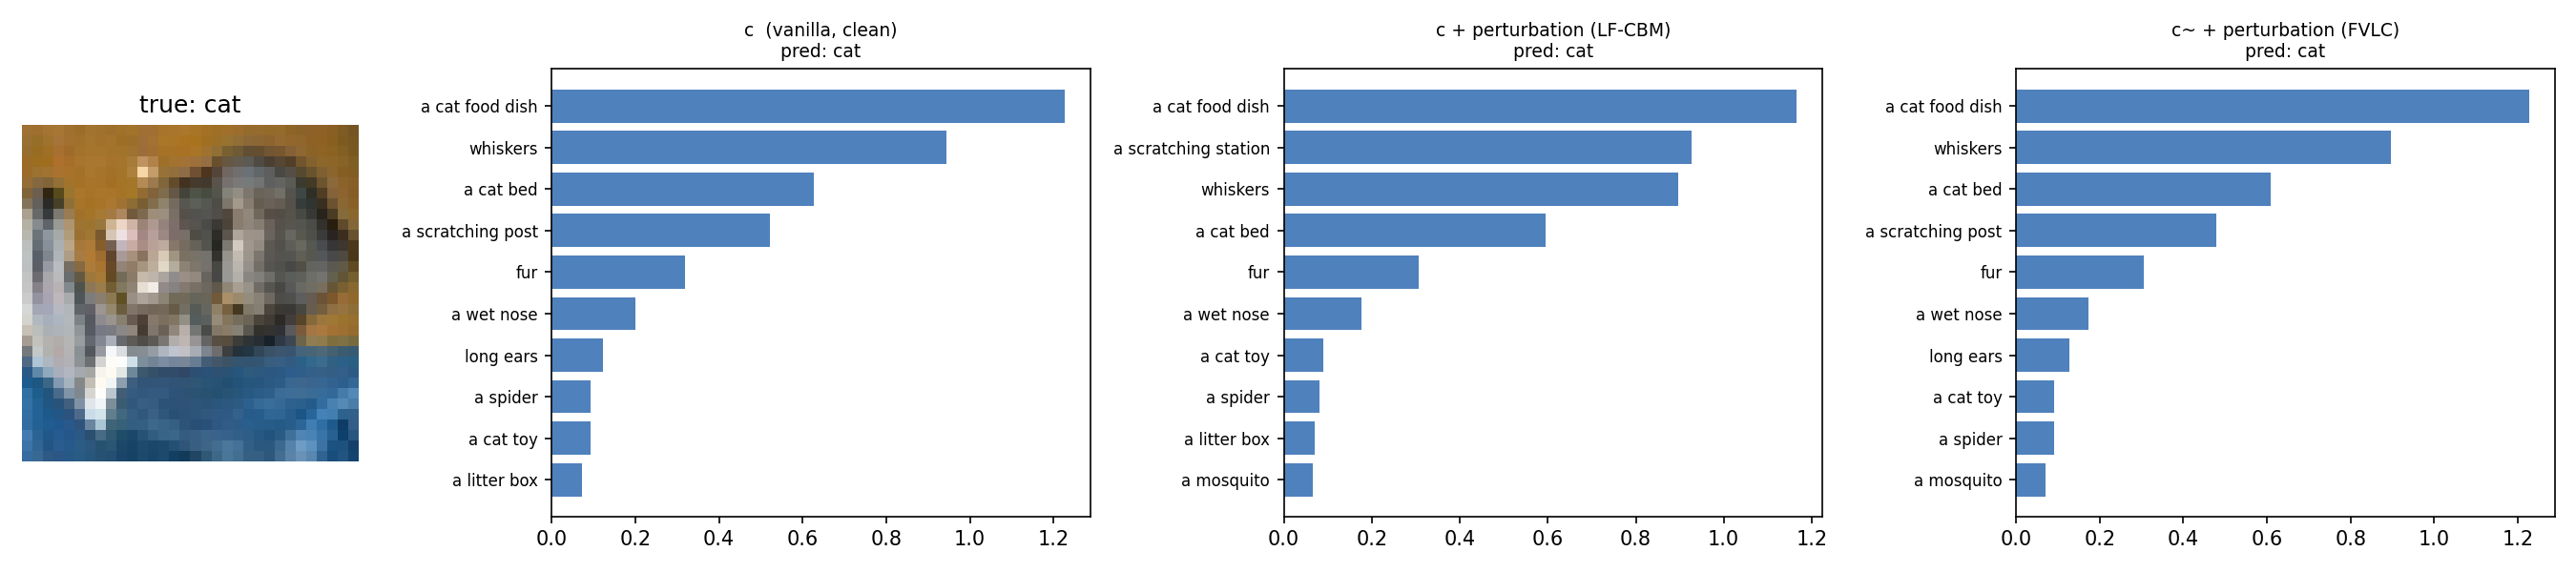

In [3]:
%cd /kaggle/working/fvlc-replication
!python run_experiments.py --dataset cifar10 --perturbations WP1_10+WP2+IP --skip_standard --out $OUT
!python visualize.py --dataset cifar10 --perturbation WP1_10+WP2+IP --index 0 --out $OUT
from IPython.display import Image, display
display(Image(f'{OUT}/cifar10/fig3_WP1_10+WP2+IP_0.png'))

/kaggle/working
Dataset cifar100 | device cuda | seed 42
100%|█████████████████████████████████████████| 169M/169M [22:47<00:00, 124kB/s]
[vanilla] 892 concepts -> 857 after CLIP cutoff                                 
  projection: best step 200, val similarity 0.6005
[vanilla] 827 concepts after interpretability cutoff
 21%|████████▎                               | 209/1000 [02:59<11:18,  1.17it/s]
(0) lambda 0.0007, loss 1.5077, acc 0.6780 [val acc 0.6509] [test acc -1.0000], sparsity 0.034740024183796854 [2873/82700], time 179.9191131591797, lr 0.1000
[vanilla] test acc 0.6509  (2873/82700 non-zero final weights)

===== WP1_10+WP2+IP =====
  projection: best step 150, val similarity 0.6016                              
[WP1_10+WP2+IP] base : acc 0.6056  TCPC 4.284e-01  TOPC 2.419e-01
    FVLC epoch   1/20  loss 5.979e-03  L1 8.707e-02  L2 3.264e-01  L3 3.015e-02  L4 1.543e-01
    FVLC epoch   5/20  loss 2.925e-03  L1 1.392e-02  L2 1.642e-01  L3 2.955e-02  L4 8.481e-02
    FVLC epoc

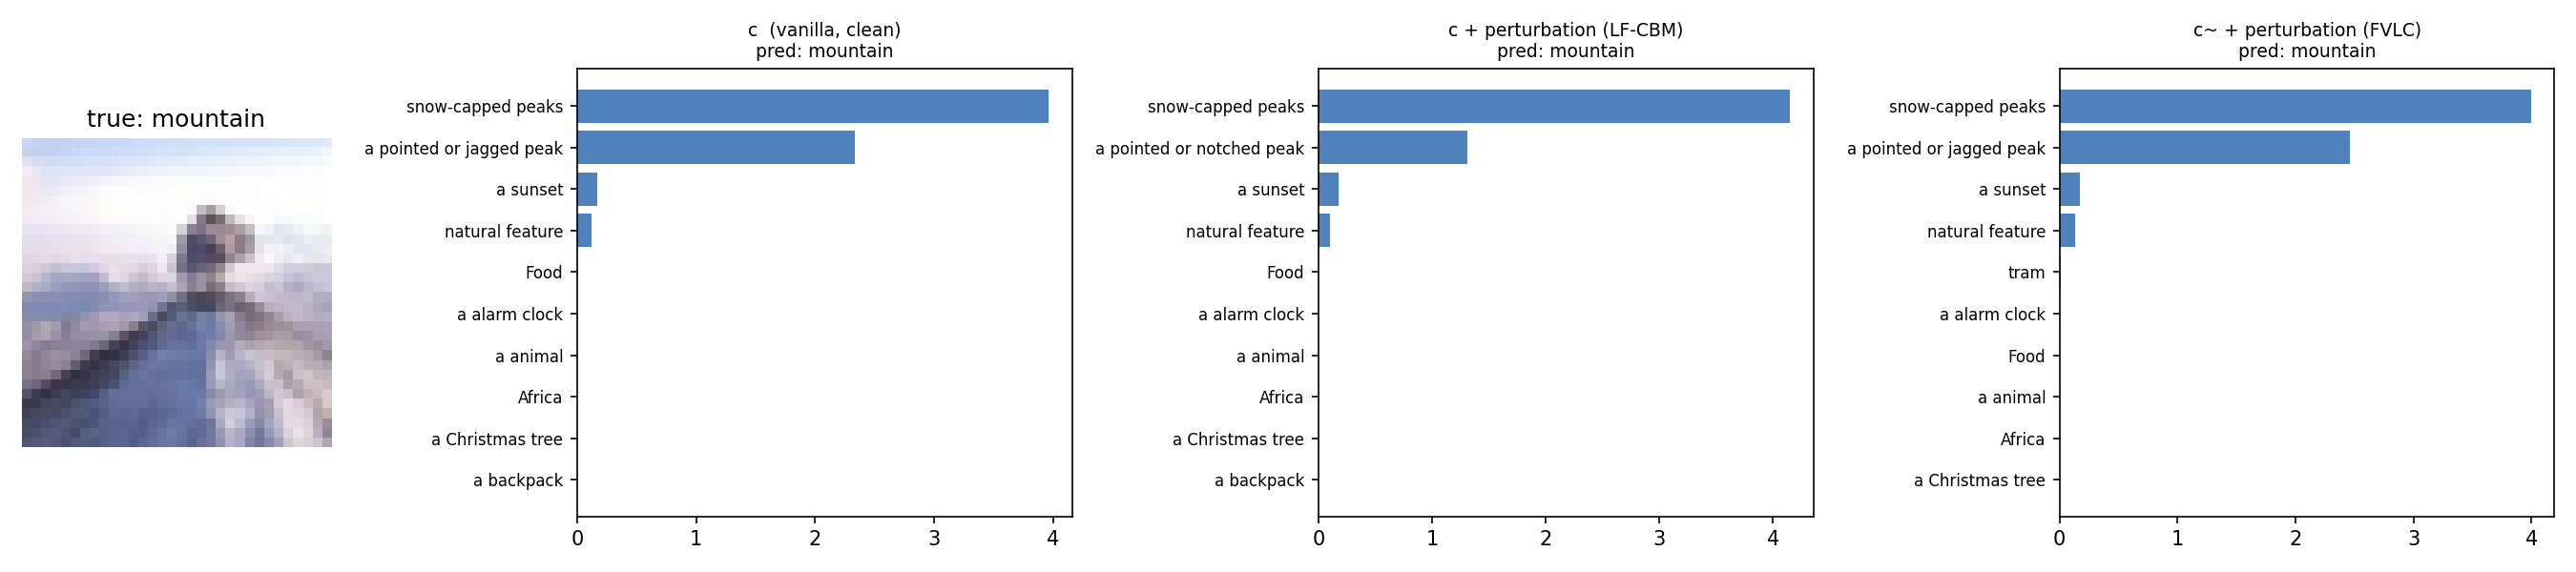

In [4]:
%cd /kaggle/working/fvlc-replication
!python run_experiments.py --dataset cifar100 --perturbations WP1_10+WP2+IP --skip_standard --out $OUT
!python visualize.py --dataset cifar100 --perturbation WP1_10+WP2+IP --index 0 --out $OUT
display(Image(f'{OUT}/cifar100/fig3_WP1_10+WP2+IP_0.png'))

/kaggle/working
CUB_200_2011.tgz    100%[===================>]   1.07G  59.7MB/s    in 19s     
{'train': 5990, 'test': 5790}
CUB ready at data/CUB
Dataset cub | device cuda | seed 42
[vanilla] 370 concepts -> 331 after CLIP cutoff                                 
  projection: best step 200, val similarity 0.4912
[vanilla] 208 concepts after interpretability cutoff
 79%|██████████████████████████████▊        | 3943/5000 [05:52<01:34, 11.18it/s]
(0) lambda 0.0002, loss 0.3317, acc 1.0000 [val acc 0.7371] [test acc -1.0000], sparsity 0.15454326923076922 [6429/41600], time 352.71855068206787, lr 0.1000
[vanilla] test acc 0.7371  (6429/41600 non-zero final weights)

===== WP1_10+WP2+IP =====
  projection: best step 250, val similarity 0.5646                              
[WP1_10+WP2+IP] base : acc 0.6675  TCPC 5.263e-01  TOPC 4.272e-01
    FVLC epoch   1/20  loss 7.776e-03  L1 1.961e-01  L2 3.473e-01  L3 9.350e-03  L4 2.248e-01
    FVLC epoch   5/20  loss 3.088e-03  L1 9.485e-03  L2 1.178

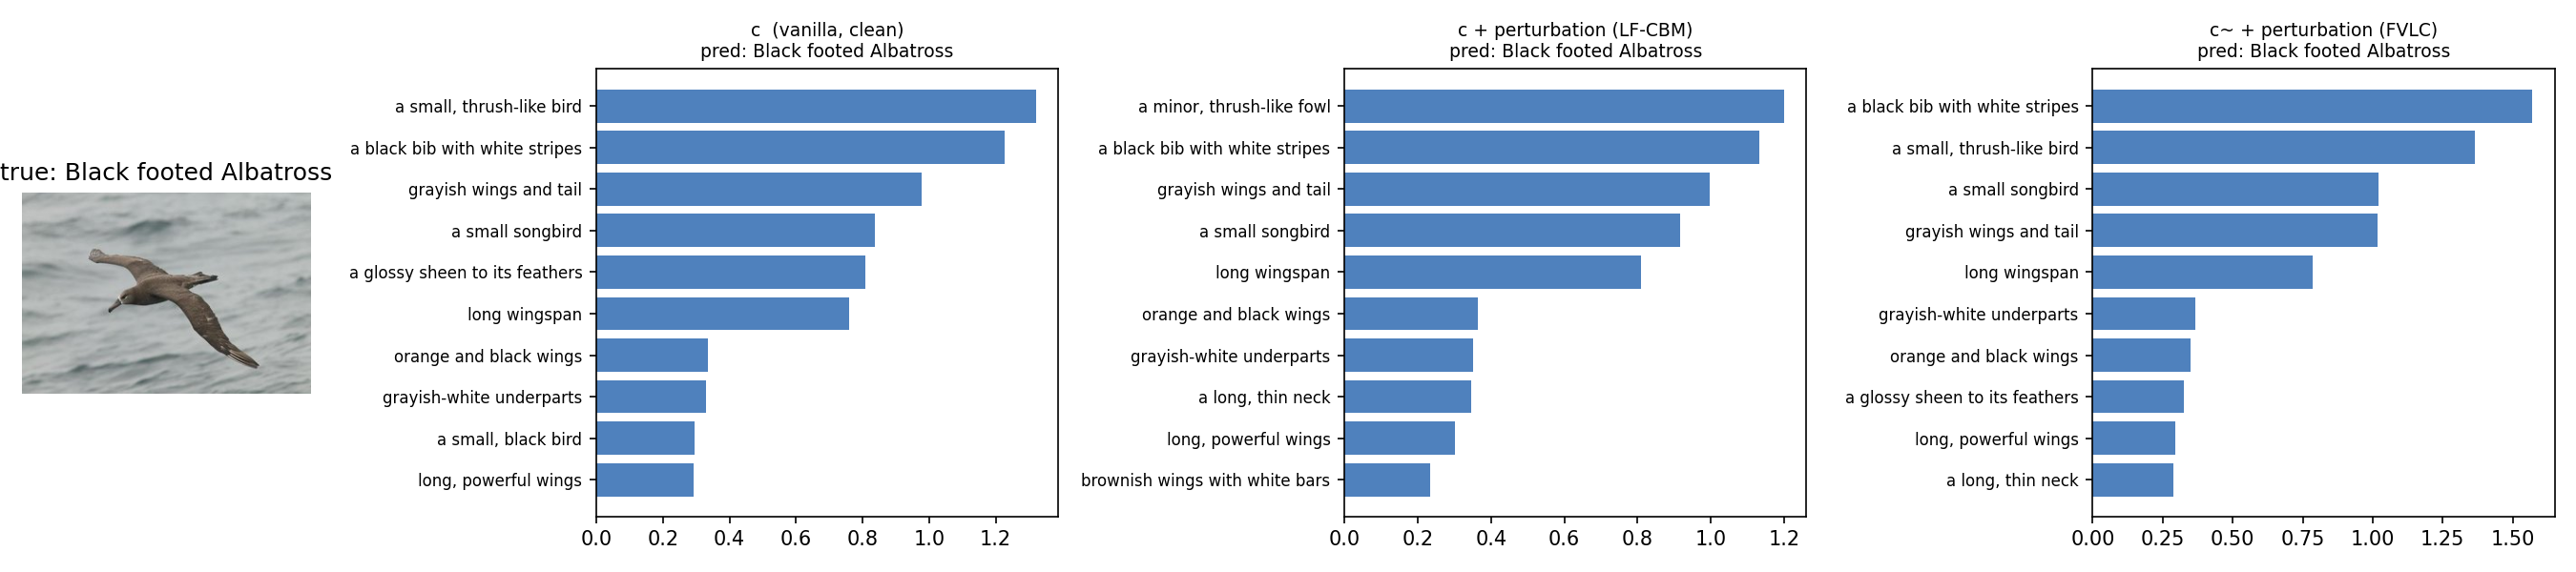

In [5]:
%cd /kaggle/working/fvlc-replication
!bash scripts/download_cub.sh
!python run_experiments.py --dataset cub --perturbations WP1_10+WP2+IP --skip_standard --out $OUT
!python visualize.py --dataset cub --perturbation WP1_10+WP2+IP --index 0 --out $OUT
display(Image(f'{OUT}/cub/fig3_WP1_10+WP2+IP_0.png'))

In [6]:
%cd /kaggle/working
!zip -qr results_fig3.zip results_fig3 -x "*/layers/*" "*/vanilla.pt"
from IPython.display import FileLink
display(FileLink('results_fig3.zip'))

/kaggle/working


/kaggle/working/results_fig3.zip